# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Kathryn Choi, Christopher Currie, Armon Haji

**Date:** 11/16/26

In [ ]:
# Your Phase 1 solution to the problem goes here.

In [61]:
# Question 1 - Check out the data set heart_failure and appropriately clean it.
import pandas as pd

heart_failure = pd.read_csv("heart_failure_clinical_records_dataset.csv")

heart_failure.head()
heart_failure.info()
heart_failure.describe()
print(f" Total Duplicate Values: {heart_failure.duplicated().sum()}")


# Since there are no null or duplicate values and the summary shows that the data types are consistent with what is expected,
# no further cleaning is necessary.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB
 Total Duplicate V

In [63]:
# Question 2 - Perform a train-test split for a specific seed (save the seed for reproducibility).
# Fit a tree and a linear model on the training data and evaluate their performance on the test data.
# Set aside the predictions these models make.

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train-test split
X = heart_failure.drop(columns='DEATH_EVENT')
y = heart_failure['DEATH_EVENT']
X_train, X_test_ref, y_train, y_test_ref = train_test_split(X, y, test_size=0.2, random_state=42)

# Fitting tree
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test_ref)
tree_prob_ref = tree.predict_proba(X_test_ref)[:, 1]

# Fitting linear model
linear = LogisticRegression(max_iter=5000)
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test_ref)
linear_prob_ref = linear.predict_proba(X_test_ref)[:, 1]

print(f"Tree Accuracy: {accuracy_score(y_test_ref, tree_pred):.3f}")
print("Linear Accuracy:", accuracy_score(y_test_ref, linear_pred))

Tree Accuracy: 0.633
Linear Accuracy: 0.8


In [64]:
# Question 3 - Repeat step 2 for three to five different seeds (save the seeds for reproducibility).
# We fit on alternative splits, but predict on the reference test set to compare predictions stably.

seeds = [10, 20, 30, 40]

tree_preds = []
linear_preds = []
tree_probs = []
linear_probs = []

for s in seeds:
    X_train_alt, X_test_alt, y_train_alt, y_test_alt = train_test_split(
        X, y, test_size=0.2, random_state=s
    )

    tree_alt = DecisionTreeClassifier(random_state=s)
    tree_alt.fit(X_train_alt, y_train_alt)

    linear_alt = LogisticRegression(max_iter=5000)
    linear_alt.fit(X_train_alt, y_train_alt)

    # Predict on the same reference set
    tree_preds.append(tree_alt.predict(X_test_ref))
    linear_preds.append(linear_alt.predict(X_test_ref))

    tree_probs.append(tree_alt.predict_proba(X_test_ref)[:, 1])
    linear_probs.append(linear_alt.predict_proba(X_test_ref)[:, 1])

    print("Seed:", s)
    print("Tree Depth:", tree_alt.get_depth())
    print("Tree Leaves:", tree_alt.get_n_leaves())
    print("Linear Coefficients:", linear_alt.coef_)
    print()


# The trees have changed slightly across different seeds, with depths having ranges between 8 and 9 and leaves between 32 and 35.
# The linear model coefficients also show changes, but many stayed relatively the same.
# The trees overall showed some variation, with the linear models remaining fairly constant.

Seed: 10
Tree Depth: 8
Tree Leaves: 32
Linear Coefficients: [[ 5.80884857e-02  2.34047007e-01  1.99950780e-04  4.13128924e-01
  -8.82482209e-02 -1.58234139e-01 -1.96855797e-06  1.26183083e+00
   5.97328703e-04 -2.79034144e-01 -1.74053575e-01 -2.21016305e-02]]

Seed: 20
Tree Depth: 9
Tree Leaves: 35
Linear Coefficients: [[ 6.07660412e-02  1.79425853e-01  1.42773069e-04  9.65525356e-02
  -9.78756270e-02 -4.56853518e-03 -2.26555971e-06  9.11006021e-01
   4.76367273e-03 -4.83394835e-01 -9.98005942e-02 -1.94426618e-02]]

Seed: 30
Tree Depth: 9
Tree Leaves: 35
Linear Coefficients: [[ 5.96918075e-02  2.38613906e-01 -4.92821138e-05  3.26188378e-01
  -7.63263029e-02 -1.58714329e-01 -3.11744702e-06  6.70176849e-01
   4.86607497e-03 -5.74332363e-01 -4.40151402e-02 -2.19720088e-02]]

Seed: 40
Tree Depth: 8
Tree Leaves: 35
Linear Coefficients: [[ 4.29027010e-02  2.52675929e-02  1.69646693e-04  2.36856664e-01
  -7.21555944e-02 -2.32693464e-01 -1.88035207e-06  7.84725095e-01
   6.96598302e-03 -4.0054

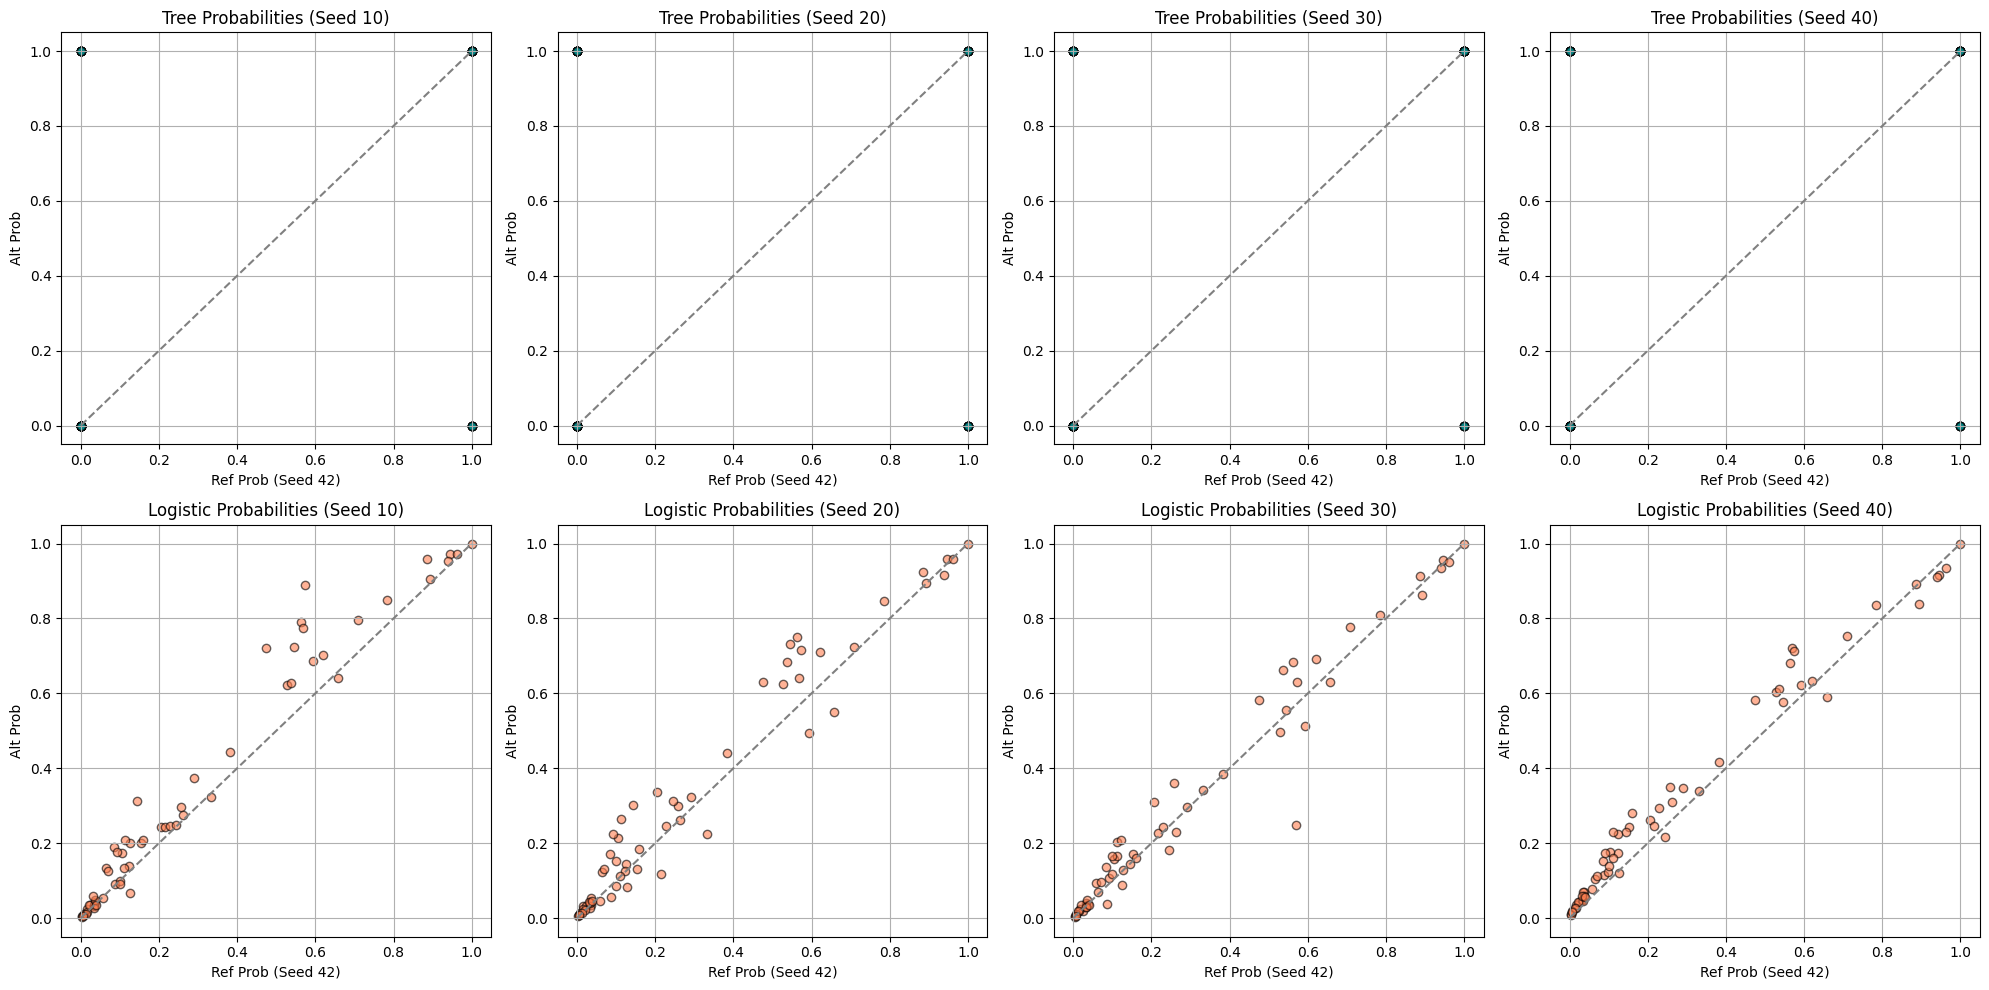

In [65]:
# Question 4a - Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, s in enumerate(seeds):
    # Tree
    axes[0, i].scatter(tree_prob_ref, tree_probs[i], color='teal', alpha=0.6, edgecolor='k')
    axes[0, i].plot([0, 1], [0, 1], '--', color='grey')
    axes[0, i].set_title(f"Tree Probabilities (Seed {s})")
    axes[0, i].set_xlabel("Ref Prob (Seed 42)")
    axes[0, i].set_ylabel("Alt Prob")
    axes[0, i].grid(True)

    # Linear
    axes[1, i].scatter(linear_prob_ref, linear_probs[i], color='coral', alpha=0.6, edgecolor='k')
    axes[1, i].plot([0, 1], [0, 1], '--', color='grey')
    axes[1, i].set_title(f"Logistic Probabilities (Seed {s})")
    axes[1, i].set_xlabel("Ref Prob (Seed 42)")
    axes[1, i].set_ylabel("Alt Prob")
    axes[1, i].grid(True)

plt.tight_layout()
plt.show()


# The predictions are reasonably similar, especially for the linear models, which show strong agreement.
# The trees, on the other hand, have some differences in their predictions.
# Overall, the linear models are more consistent than the trees.

In [66]:
# Question 4b - Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models.
# Are they highly correlated or not?

import numpy as np

for i in range(len(seeds)):
    print("Seed:", seeds[i])
    print("Tree Correlation:", np.corrcoef(tree_pred, tree_preds[i])[0, 1])
    print("Linear Correlation:", np.corrcoef(linear_pred, linear_preds[i])[0, 1])
    print()


# The trees have correlations ranging from 0.18- 0.42, and the linear models have correlations ranging from 0.92 - 1.0, which explains that the linear models are highly correlated and the trees are much lower.
# This explains that the linear models make much more consistent predictions across different seeds.

Seed: 10
Tree Correlation: 0.34757851759765357
Linear Correlation: 0.9604585468176341

Seed: 20
Tree Correlation: 0.1755241554314476
Linear Correlation: 0.917920656634747

Seed: 30
Tree Correlation: 0.41694736874220417
Linear Correlation: 0.8754162937439077

Seed: 40
Tree Correlation: 0.36942568221248373
Linear Correlation: 0.9604585468176341



In [67]:
# Question 4c - Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models.
# Is the intercept close to zero?
# Is the slope close to 1?
# Is the R^2 close to 1?

from sklearn.linear_model import LinearRegression

# Running linear regression
for i in range(len(seeds)):
    reg_tree = LinearRegression()
    reg_tree.fit(tree_pred.reshape(-1, 1), tree_preds[i])

    print("Seed:", seeds[i])
    print("Tree Intercept:", reg_tree.intercept_)
    print("Tree Slope:", reg_tree.coef_[0])
    print("Tree R2:", reg_tree.score(tree_pred.reshape(-1, 1), tree_preds[i]))

    reg_linear = LinearRegression()
    reg_linear.fit(linear_pred.reshape(-1, 1), linear_preds[i])

    print("Linear Intercept:", reg_linear.intercept_)
    print("Linear Slope:", reg_linear.coef_[0])
    print("Linear R2:", reg_linear.score(linear_pred.reshape(-1, 1), linear_preds[i]))
    print()


# The R2 values range from 0.85 to 1.0, slopes are very close to 1, and the linear models have intercepts close to 0.
# The trees have intercepts around 0.3, slopes significantly lower than 1, and R2 values ranging from 0.03 to 0.17.
# These results, looked at together, show that the linear models make much more similar predictions across the different seeds compared to the different predictions across trees varying more.

Seed: 10
Tree Intercept: 0.2682926829268293
Tree Slope: 0.3632862644415919
Tree R2: 0.12081082589538283
Linear Intercept: 0.023255813953488302
Linear Slope: 0.9767441860465119
Linear R2: 0.9224806201550387

Seed: 20
Tree Intercept: 0.34146341463414637
Tree Slope: 0.1848523748395379
Tree R2: 0.03080872913992294
Linear Intercept: 0.023255813953488302
Linear Slope: 0.9179206566347471
Linear R2: 0.8425783318767649

Seed: 30
Tree Intercept: 0.29268292682926833
Tree Slope: 0.44415917843388963
Tree R2: 0.17384510830104727
Linear Intercept: 0.023255813953488247
Linear Slope: 0.8590971272229827
Linear R2: 0.7663536873523195

Seed: 40
Tree Intercept: 0.29268292682926833
Tree Slope: 0.3915275994865212
Tree R2: 0.13647533467815876
Linear Intercept: 0.023255813953488302
Linear Slope: 0.9767441860465119
Linear R2: 0.9224806201550387



**Question 5 - Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?**



The linear models produced pretty similar coefficients and predictions. Their prediction correlations were mostly in the range above 0.97 with high R^2 values from 0.95 to 0.98, showing that they were consistent. The decision trees changed more between splits, having different numbers of leaves and depths. Their prediction correlations were lower, ranging from 0.18 to 0.42. All of this evidence suggests that the linear models were more stable than decision trees in this instance.


**Question 6 - True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."**



The answer is false in this instance. Though the decision trees looked different across the train-test splits, their predictions were not very similar. The correlations between their predictions ranged from about 0.17 to 0.42 with R^2 values from 0.03 to 0.17, showing a pretty low level of consistency. This being said, the linear models had much higher correlations, mostly above 0.92. This suggests that the differences in how models look can also lead to some differences in their predictions. This seems especially true in the case of decision trees.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]